# Practical 6 — Diffusion-Based Generation

**Enrollment:** BT24S05F007

## Aim
Study forward and reverse diffusion and generate new samples by gradually denoising random noise. The same idea powers systems such as Stable Diffusion; this practical uses a small 2D model so the steps stay visible and runnable offline.

## Concept
**Forward:** clean point → add noise over many steps → nearly pure noise.  
**Reverse:** noise → predict and remove a little noise at each step → a new point that looks real.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import torch.nn as nn

SEED = 7
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cpu")


## Target distribution and noise schedule


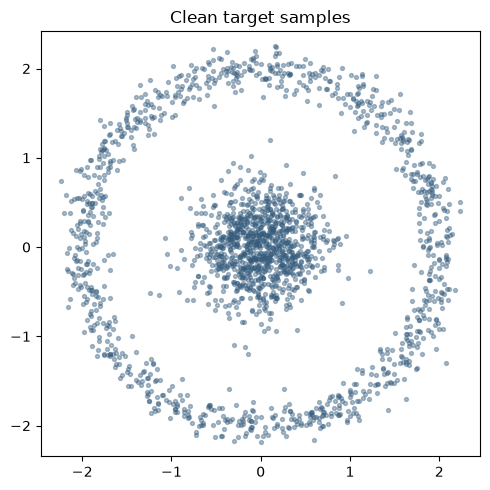

alpha_bar[0]= 0.9991999864578247 alpha_bar[-1]= 0.5366905927658081


In [2]:
def ring_and_blob(count=2000):
    angles = np.random.uniform(0, 2 * np.pi, size=count // 2)
    radii = np.random.normal(2.0, 0.12, size=count // 2)
    ring = np.stack([radii * np.cos(angles), radii * np.sin(angles)], axis=1)
    blob = np.random.normal([0.0, 0.0], 0.35, size=(count - count // 2, 2))
    return np.vstack([ring, blob]).astype(np.float32)

clean = ring_and_blob()
clean_t = torch.tensor(clean, dtype=torch.float32)

steps = 40
beta = torch.linspace(0.0008, 0.03, steps)
alpha = 1.0 - beta
alpha_bar = torch.cumprod(alpha, dim=0)

plt.figure(figsize=(5.0, 5.0))
plt.scatter(clean[:, 0], clean[:, 1], s=8, alpha=0.4, c="#355c7d")
plt.title("Clean target samples")
plt.axis("equal")
plt.tight_layout()
plt.show()
print("alpha_bar[0]=", float(alpha_bar[0]), "alpha_bar[-1]=", float(alpha_bar[-1]))


## Forward diffusion
At step `t`, a clean point `x0` becomes a noisy version using the closed form  
`x_t = sqrt(ᾱ_t) x0 + sqrt(1 - ᾱ_t) ε`.


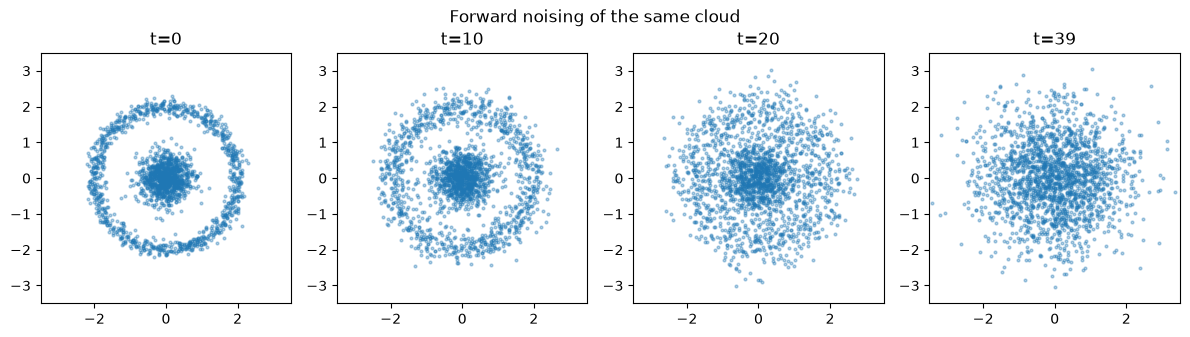

In [3]:
def add_noise(x0, t_index, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    a = alpha_bar[t_index].view(-1, 1)
    return torch.sqrt(a) * x0 + torch.sqrt(1.0 - a) * noise, noise

demo_index = torch.tensor([0, 10, 20, 39])
fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, t in zip(axes, demo_index.tolist()):
    noisy, _ = add_noise(clean_t, torch.full((clean_t.shape[0],), t))
    ax.scatter(noisy[:, 0], noisy[:, 1], s=4, alpha=0.35)
    ax.set_title(f"t={t}")
    ax.set_xlim(-3.5, 3.5)
    ax.set_ylim(-3.5, 3.5)
    ax.set_aspect("equal")
plt.suptitle("Forward noising of the same cloud")
plt.tight_layout()
plt.show()


## Denoiser network
A small MLP predicts the noise that was added. Training pairs are random times `t` and the matching noise.


In [4]:
class NoisePredictor(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, 64),
            nn.SiLU(),
            nn.Linear(64, 64),
            nn.SiLU(),
            nn.Linear(64, 2),
        )

    def forward(self, noisy_points, t_float):
        features = torch.cat([noisy_points, t_float], dim=1)
        return self.net(features)

model = NoisePredictor().to(device)
opt = torch.optim.Adam(model.parameters(), lr=0.002)
losses = []
batch_size = 128
train_steps = 2500

for step in range(1, train_steps + 1):
    pick = torch.randint(0, clean_t.shape[0], (batch_size,))
    x0 = clean_t[pick]
    t = torch.randint(0, steps, (batch_size,))
    xt, noise = add_noise(x0, t)
    t_float = (t.float() / (steps - 1)).unsqueeze(1)
    pred = model(xt, t_float)
    loss = torch.mean((pred - noise) ** 2)
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(float(loss.item()))
    if step % 500 == 0:
        print(f"step {step:4d} | noise MSE {loss.item():.4f}")


step  500 | noise MSE 0.8779
step 1000 | noise MSE 0.8457


step 1500 | noise MSE 0.8861
step 2000 | noise MSE 0.7042


step 2500 | noise MSE 0.9140


## Reverse sampling
Start from pure noise and walk backward from `t = T-1` to `0`, subtracting the predicted noise at each step.


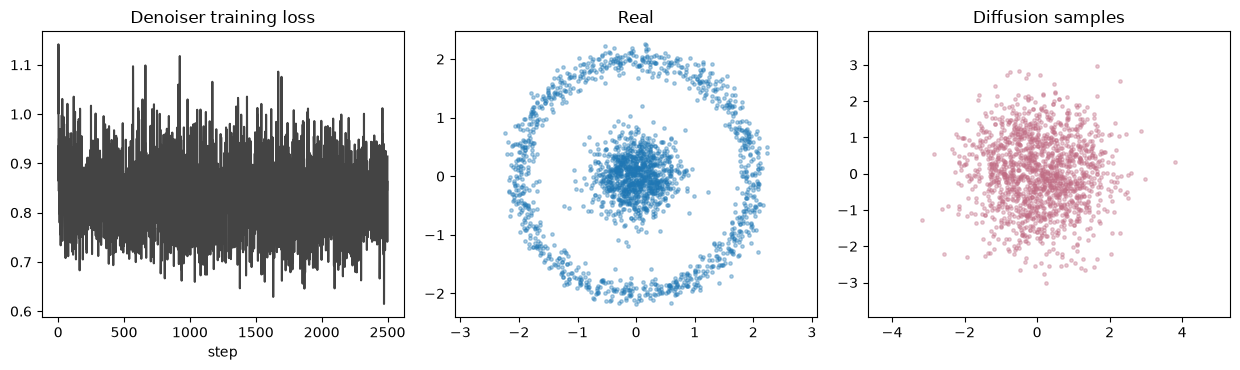

Generated shape: (1500, 2)
Generated mean: [0.045 0.008]


In [5]:
@torch.no_grad()
def sample(count=1500):
    x = torch.randn(count, 2)
    for t in reversed(range(steps)):
        t_tensor = torch.full((count,), t)
        t_float = (t_tensor.float() / (steps - 1)).unsqueeze(1)
        eps = model(x, t_float)
        a = alpha[t]
        ab = alpha_bar[t]
        x = (1.0 / torch.sqrt(a)) * (x - ((1.0 - a) / torch.sqrt(1.0 - ab)) * eps)
        if t > 0:
            x = x + torch.sqrt(beta[t]) * torch.randn_like(x)
    return x.cpu().numpy()

generated = sample()

fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.8))
axes[0].plot(losses, color="#444")
axes[0].set_title("Denoiser training loss")
axes[0].set_xlabel("step")
axes[1].scatter(clean[:, 0], clean[:, 1], s=6, alpha=0.35)
axes[1].set_title("Real")
axes[1].axis("equal")
axes[2].scatter(generated[:, 0], generated[:, 1], s=6, alpha=0.35, c="#c06c84")
axes[2].set_title("Diffusion samples")
axes[2].axis("equal")
plt.tight_layout()
plt.show()
print("Generated shape:", generated.shape)
print("Generated mean:", np.round(generated.mean(axis=0), 3))


## Link to Stable Diffusion
Stable Diffusion uses the same forward/reverse idea on image latents, with a U-Net denoiser and a text encoder for prompts. This practical keeps the math on 2D points so the schedule, noise prediction, and reverse walk are easy to inspect without a large GPU download.


## Conclusion
Forward diffusion destroys structure with a known schedule. A network trained to predict that noise can reverse the walk and invent new samples from the target distribution. That denoising loop is the core of diffusion-based image generators such as Stable Diffusion.


## Run results

Outputs captured from the executed notebook.

```
alpha_bar[0]= 0.9991999864578247 alpha_bar[-1]= 0.5366905927658081
```

```
step  500 | noise MSE 0.8779
step 1000 | noise MSE 0.8457
step 1500 | noise MSE 0.8861
step 2000 | noise MSE 0.7042
step 2500 | noise MSE 0.9140
```

```
Generated shape: (1500, 2)
Generated mean: [0.045 0.008]
```

**figure 1**

![figure 1](results/GenAI_Practical_06_fig1.png)

**figure 2**

![figure 2](results/GenAI_Practical_06_fig2.png)

**figure 3**

![figure 3](results/GenAI_Practical_06_fig3.png)
